# Gelecek dört hafta kaç sipariş gelecek?

Depo kaynak planı için 266 günlük sipariş geçmişi var. Haftanın günleri farklı ve talep zamanla artıyor. Son 28 gün final test olarak ayrılıyor. Yönetici, daha karmaşık modelin aynı ufuktaki güçlü bir tabandan iyi olup olmadığını görmek istiyor. Kırılma senaryosunda final dönemde beklenmeyen yeni seviye oluşuyor.

**Karar:** 28 günlük kaynak planında SARIMA’yı mı, mevsimsel naif tabanı mı kullanmak için kanıt var?

**Birim:** Zaman birimi: takvim günü. Hedef: aynı kesimden gelecekteki 28 günün sipariş adedi.

**Yöntem:** Eğitim, model seçimi ve final testi tarihleriyle ayır. Adayları sadece seçim döneminde karşılaştır. Seçileni geçmişte yeniden eğit, tek kesimden 28 adım tahmin et; naif tabana da aynı bilgi erişimini ver.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: Düzenli haftalık yapı

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                       Ölçü         Değer
 Eğitim / seçim / test günü 210 / 28 / 28
            SARIMA test MAE      4.608913
             Taban test MAE     10.142857
Finalde gözlenen %95 kapsam      0.964286
  Artık Ljung–Box p · lag14      0.925431

Aday seçimi yalnız validasyonda
    order seasonal_order   train_AIC  validation_MAE  converged
(1, 0, 0)   (0, 1, 1, 7) 1265.306257        6.743045       True
(0, 1, 1)   (0, 1, 1, 7) 1297.354560        6.813238       True

Aynı final döneminde karşılaştırma
          model  test_MAE  test_RMSE
 Mevsimsel naif 10.142857  11.871334
Seçilmiş SARIMA  4.608913   5.459858

Karar: Final test MAE: SARIMA 4.61, taban 10.14 adet. Seçilmiş model bu testte daha düşük hata verdi; sonraki dönemi garanti etmez.

Sınır: Sentetik tek günlük seri; sınırlı iki adaylı öğretim araması. Normal hata tabanlı model aralıkları kayma altında garanti sağlamaz. Kırılma senaryosunda final dönemdeki yeni seviye eğitime verilmez. Gerçek operasyon ayrıca takvim, kampa

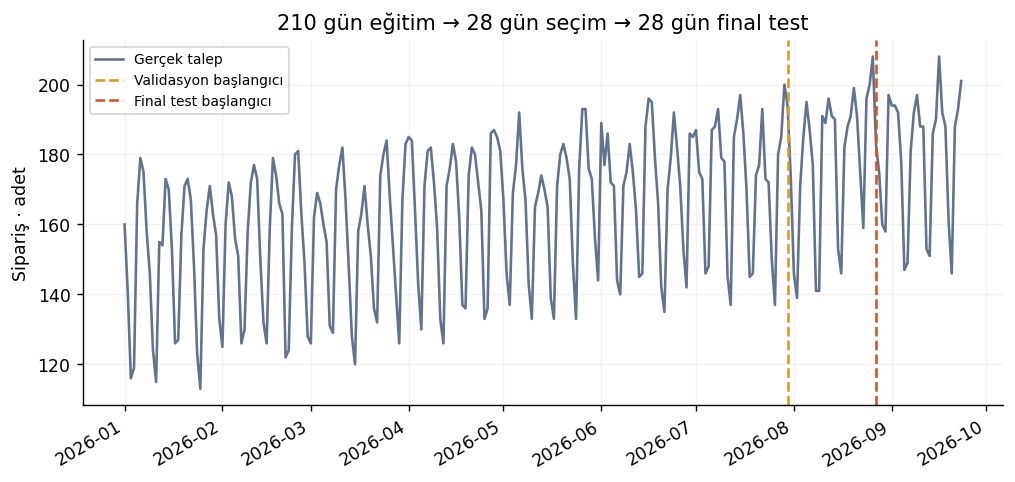

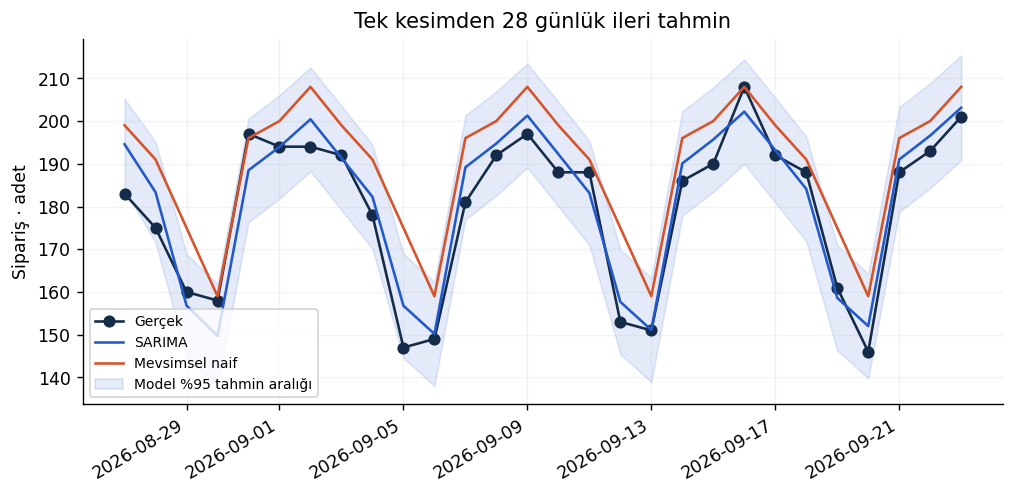

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def demand(scenario='default'):
 rng=np.random.default_rng(260804);n=266;dates=pd.date_range('2026-01-01',periods=n,freq='D');time=np.arange(n);weekly=np.array([8,15,20,10,0,-25,-30]);noise=np.zeros(n)
 for t in range(1,n):noise[t]=.4*noise[t-1]+rng.normal(0,5)
 y=150+.12*time+weekly[dates.dayofweek]+noise
 if scenario!='default':y[238:]+=25
 series=pd.Series(np.round(y),index=dates,name='orders');train,val,test=series.iloc[:210],series.iloc[210:238],series.iloc[238:];candidates=[((1,0,0),(0,1,1,7)),((0,1,1),(0,1,1,7))];rows=[];fits=[]
 for order,season in candidates:
  fit=SARIMAX(train,order=order,seasonal_order=season,trend='c',enforce_stationarity=True,enforce_invertibility=True).fit(disp=False,maxiter=300);pred=fit.get_forecast(len(val)).predicted_mean;mae=np.mean(abs(val-pred));converged=bool(fit.mle_retvals.get('converged',False));rows.append([str(order),str(season),float(fit.aic),float(mae),converged]);fits.append(fit)
 eligible=[i for i in range(len(fits))if rows[i][-1]]
 if not eligible:raise RuntimeError('Adayların hiçbiri yakınsamadı; model başarı diye sunulamaz.')
 best=min(eligible,key=lambda i:rows[i][3]);order,season=candidates[best];history=pd.concat([train,val]);final=SARIMAX(history,order=order,seasonal_order=season,trend='c',enforce_stationarity=True,enforce_invertibility=True).fit(disp=False,maxiter=300)
 if not final.mle_retvals.get('converged',False):raise RuntimeError('Final model yakınsamadı.')
 forecast=final.get_forecast(len(test));pred=forecast.predicted_mean;ci=forecast.conf_int(alpha=.05);# frozen-origin multi-step seasonal naive repeats the final observed week, no actual test values used
 baseline=np.tile(history.iloc[-7:].values,4);mae=lambda p:float(np.mean(abs(test.values-np.asarray(p))));rmse=lambda p:float(np.sqrt(np.mean((test.values-np.asarray(p))**2)));coverage=float(np.mean((test.values>=ci.iloc[:,0].values)&(test.values<=ci.iloc[:,1].values)));errors=final.resid.iloc[21:];lb=acorr_ljungbox(errors,lags=[14],model_df=2,return_df=True).iloc[0].lb_pvalue
 raw=pd.DataFrame({'date':dates.strftime('%Y-%m-%d'),'orders':series.values,'partition':['train']*210+['validation']*28+['final_test']*28});validation=pd.DataFrame(rows,columns=['order','seasonal_order','train_AIC','validation_MAE','converged']);evaluation=pd.DataFrame([['Mevsimsel naif',mae(baseline),rmse(baseline)],['Seçilmiş SARIMA',mae(pred),rmse(pred)]],columns=['model','test_MAE','test_RMSE']);predframe=pd.DataFrame({'date':test.index.strftime('%Y-%m-%d'),'actual':test.values,'seasonal_naive':baseline,'sarima':pred.values,'lower95':ci.iloc[:,0].values,'upper95':ci.iloc[:,1].values})
 assert list(pred.index)==list(test.index) and history.index.max()<test.index.min();assert len(test)==28
 fig,ax=plt.subplots(figsize=(9.5,4.3));ax.plot(series,label='Gerçek talep',color='#61738D');ax.axvline(val.index[0],color='#D99A28',ls='--',label='Validasyon başlangıcı');ax.axvline(test.index[0],color='#D5542B',ls='--',label='Final test başlangıcı');ax.set(ylabel='Sipariş · adet',title='210 gün eğitim → 28 gün seçim → 28 gün final test');ax.legend(fontsize=8);fig.autofmt_xdate()
 fig2,ax2=plt.subplots(figsize=(9.5,4.3));ax2.plot(test.index,test.values,'o-',label='Gerçek',color='#142C49');ax2.plot(test.index,pred.values,label='SARIMA',color='#235ACB');ax2.plot(test.index,baseline,label='Mevsimsel naif',color='#D5542B');ax2.fill_between(test.index,ci.iloc[:,0].values,ci.iloc[:,1].values,color='#235ACB',alpha=.12,label='Model %95 tahmin aralığı');ax2.set(ylabel='Sipariş · adet',title='Tek kesimden 28 günlük ileri tahmin');ax2.legend(fontsize=8);fig2.autofmt_xdate()
 decision=f'Final test MAE: SARIMA {mae(pred):.2f}, taban {mae(baseline):.2f} adet. '+('Seçilmiş model bu testte daha düşük hata verdi; sonraki dönemi garanti etmez.'if mae(pred)<mae(baseline)else'Tabanı geçemedi; daha karmaşık olduğu için bu modeli seçme.')
 return dict(metrics={'Eğitim / seçim / test günü':'210 / 28 / 28','SARIMA test MAE':mae(pred),'Taban test MAE':mae(baseline),'Finalde gözlenen %95 kapsam':coverage,'Artık Ljung–Box p · lag14':float(lb)},tables=[tbl(validation,'Aday seçimi yalnız validasyonda'),tbl(evaluation,'Aynı final döneminde karşılaştırma')],figures=[('Kesim tarihleri modelden önce belirlenir; final test model seçmek için geri kullanılmaz.',fig),('Tahminler aynı kesimden üretilir; naif taban da gelecekteki gerçekleşenleri kullanmaz.',fig2)],frames={'gunluk_talep':raw,'final_tahminler':predframe},steps=['İlk 210 günü eğitim, sonraki 28 günü model seçimi, son 28 günü final test olarak ayır.','Önceden seçilmiş iki adayın validasyon MAE’sini ve yakınsamasını kontrol et; seçilen aileyi ilk 238 günde yeniden eğit.','Aynı kesimden 28 adım tahmin et. Mevsimsel naif taban son gözlenen haftayı tekrar eder; MAE/RMSE ve tahmin aralığı kapsamını aynı tarihlerde kıyasla.'],decision=decision,diagnostics={'train_end':str(train.index[-1].date()),'selection_end':str(val.index[-1].date()),'test_start':str(test.index[0].date()),'test_n':len(test),'selected_order':list(order),'selected_season':list(season),'validation_rows':rows,'final_converged':True,'mae_sarima':mae(pred),'mae_baseline':mae(baseline),'coverage':coverage,'ljung_box_p':float(lb)},limit='Sentetik tek günlük seri; sınırlı iki adaylı öğretim araması. Normal hata tabanlı model aralıkları kayma altında garanti sağlamaz. Kırılma senaryosunda final dönemdeki yeni seviye eğitime verilmez. Gerçek operasyon ayrıca takvim, kampanya, kesintiler ve maliyet temelli ufuk ister.')

result=demand('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: Final dönemde yeni seviye

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                       Ölçü         Değer
 Eğitim / seçim / test günü 210 / 28 / 28
            SARIMA test MAE     23.075954
             Taban test MAE     15.142857
Finalde gözlenen %95 kapsam           0.0
  Artık Ljung–Box p · lag14      0.925431

Aday seçimi yalnız validasyonda
    order seasonal_order   train_AIC  validation_MAE  converged
(1, 0, 0)   (0, 1, 1, 7) 1265.306257        6.743045       True
(0, 1, 1)   (0, 1, 1, 7) 1297.354560        6.813238       True

Aynı final döneminde karşılaştırma
          model  test_MAE  test_RMSE
 Mevsimsel naif 15.142857  16.197442
Seçilmiş SARIMA 23.075954  23.634885

Karar: Final test MAE: SARIMA 23.08, taban 15.14 adet. Tabanı geçemedi; daha karmaşık olduğu için bu modeli seçme.

Sınır: Sentetik tek günlük seri; sınırlı iki adaylı öğretim araması. Normal hata tabanlı model aralıkları kayma altında garanti sağlamaz. Kırılma senaryosunda final dönemdeki yeni seviye eğitime verilmez. Gerçek operasyon ayrıca takvim, kampanya, kesintiler v

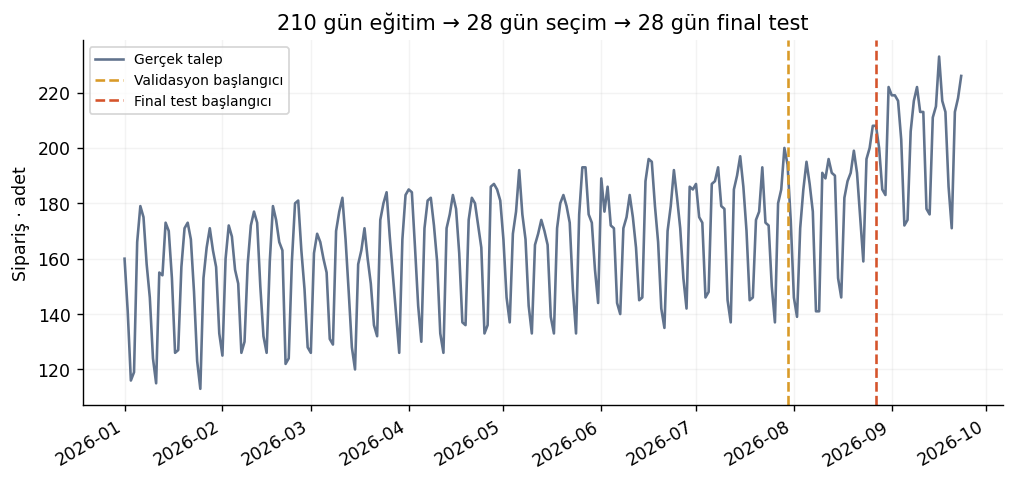

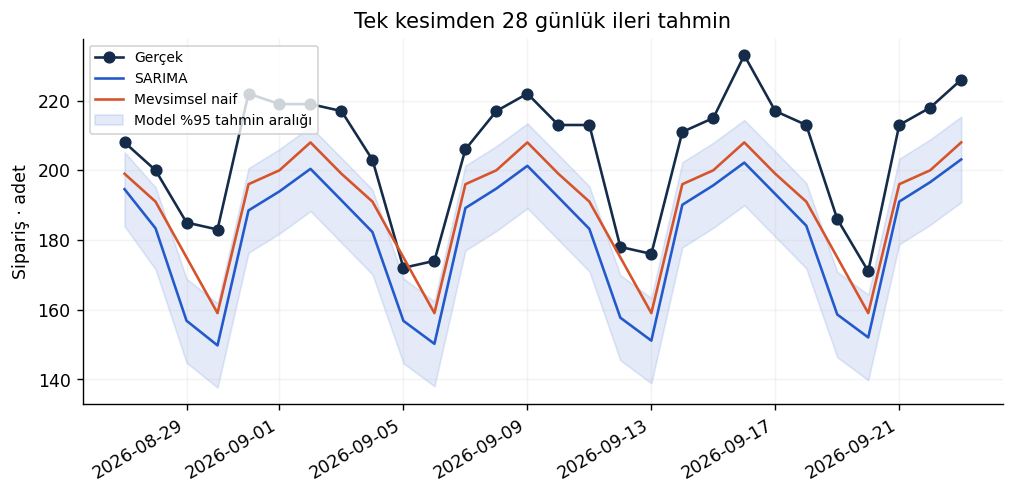

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def demand(scenario='default'):
 rng=np.random.default_rng(260804);n=266;dates=pd.date_range('2026-01-01',periods=n,freq='D');time=np.arange(n);weekly=np.array([8,15,20,10,0,-25,-30]);noise=np.zeros(n)
 for t in range(1,n):noise[t]=.4*noise[t-1]+rng.normal(0,5)
 y=150+.12*time+weekly[dates.dayofweek]+noise
 if scenario!='default':y[238:]+=25
 series=pd.Series(np.round(y),index=dates,name='orders');train,val,test=series.iloc[:210],series.iloc[210:238],series.iloc[238:];candidates=[((1,0,0),(0,1,1,7)),((0,1,1),(0,1,1,7))];rows=[];fits=[]
 for order,season in candidates:
  fit=SARIMAX(train,order=order,seasonal_order=season,trend='c',enforce_stationarity=True,enforce_invertibility=True).fit(disp=False,maxiter=300);pred=fit.get_forecast(len(val)).predicted_mean;mae=np.mean(abs(val-pred));converged=bool(fit.mle_retvals.get('converged',False));rows.append([str(order),str(season),float(fit.aic),float(mae),converged]);fits.append(fit)
 eligible=[i for i in range(len(fits))if rows[i][-1]]
 if not eligible:raise RuntimeError('Adayların hiçbiri yakınsamadı; model başarı diye sunulamaz.')
 best=min(eligible,key=lambda i:rows[i][3]);order,season=candidates[best];history=pd.concat([train,val]);final=SARIMAX(history,order=order,seasonal_order=season,trend='c',enforce_stationarity=True,enforce_invertibility=True).fit(disp=False,maxiter=300)
 if not final.mle_retvals.get('converged',False):raise RuntimeError('Final model yakınsamadı.')
 forecast=final.get_forecast(len(test));pred=forecast.predicted_mean;ci=forecast.conf_int(alpha=.05);# frozen-origin multi-step seasonal naive repeats the final observed week, no actual test values used
 baseline=np.tile(history.iloc[-7:].values,4);mae=lambda p:float(np.mean(abs(test.values-np.asarray(p))));rmse=lambda p:float(np.sqrt(np.mean((test.values-np.asarray(p))**2)));coverage=float(np.mean((test.values>=ci.iloc[:,0].values)&(test.values<=ci.iloc[:,1].values)));errors=final.resid.iloc[21:];lb=acorr_ljungbox(errors,lags=[14],model_df=2,return_df=True).iloc[0].lb_pvalue
 raw=pd.DataFrame({'date':dates.strftime('%Y-%m-%d'),'orders':series.values,'partition':['train']*210+['validation']*28+['final_test']*28});validation=pd.DataFrame(rows,columns=['order','seasonal_order','train_AIC','validation_MAE','converged']);evaluation=pd.DataFrame([['Mevsimsel naif',mae(baseline),rmse(baseline)],['Seçilmiş SARIMA',mae(pred),rmse(pred)]],columns=['model','test_MAE','test_RMSE']);predframe=pd.DataFrame({'date':test.index.strftime('%Y-%m-%d'),'actual':test.values,'seasonal_naive':baseline,'sarima':pred.values,'lower95':ci.iloc[:,0].values,'upper95':ci.iloc[:,1].values})
 assert list(pred.index)==list(test.index) and history.index.max()<test.index.min();assert len(test)==28
 fig,ax=plt.subplots(figsize=(9.5,4.3));ax.plot(series,label='Gerçek talep',color='#61738D');ax.axvline(val.index[0],color='#D99A28',ls='--',label='Validasyon başlangıcı');ax.axvline(test.index[0],color='#D5542B',ls='--',label='Final test başlangıcı');ax.set(ylabel='Sipariş · adet',title='210 gün eğitim → 28 gün seçim → 28 gün final test');ax.legend(fontsize=8);fig.autofmt_xdate()
 fig2,ax2=plt.subplots(figsize=(9.5,4.3));ax2.plot(test.index,test.values,'o-',label='Gerçek',color='#142C49');ax2.plot(test.index,pred.values,label='SARIMA',color='#235ACB');ax2.plot(test.index,baseline,label='Mevsimsel naif',color='#D5542B');ax2.fill_between(test.index,ci.iloc[:,0].values,ci.iloc[:,1].values,color='#235ACB',alpha=.12,label='Model %95 tahmin aralığı');ax2.set(ylabel='Sipariş · adet',title='Tek kesimden 28 günlük ileri tahmin');ax2.legend(fontsize=8);fig2.autofmt_xdate()
 decision=f'Final test MAE: SARIMA {mae(pred):.2f}, taban {mae(baseline):.2f} adet. '+('Seçilmiş model bu testte daha düşük hata verdi; sonraki dönemi garanti etmez.'if mae(pred)<mae(baseline)else'Tabanı geçemedi; daha karmaşık olduğu için bu modeli seçme.')
 return dict(metrics={'Eğitim / seçim / test günü':'210 / 28 / 28','SARIMA test MAE':mae(pred),'Taban test MAE':mae(baseline),'Finalde gözlenen %95 kapsam':coverage,'Artık Ljung–Box p · lag14':float(lb)},tables=[tbl(validation,'Aday seçimi yalnız validasyonda'),tbl(evaluation,'Aynı final döneminde karşılaştırma')],figures=[('Kesim tarihleri modelden önce belirlenir; final test model seçmek için geri kullanılmaz.',fig),('Tahminler aynı kesimden üretilir; naif taban da gelecekteki gerçekleşenleri kullanmaz.',fig2)],frames={'gunluk_talep':raw,'final_tahminler':predframe},steps=['İlk 210 günü eğitim, sonraki 28 günü model seçimi, son 28 günü final test olarak ayır.','Önceden seçilmiş iki adayın validasyon MAE’sini ve yakınsamasını kontrol et; seçilen aileyi ilk 238 günde yeniden eğit.','Aynı kesimden 28 adım tahmin et. Mevsimsel naif taban son gözlenen haftayı tekrar eder; MAE/RMSE ve tahmin aralığı kapsamını aynı tarihlerde kıyasla.'],decision=decision,diagnostics={'train_end':str(train.index[-1].date()),'selection_end':str(val.index[-1].date()),'test_start':str(test.index[0].date()),'test_n':len(test),'selected_order':list(order),'selected_season':list(season),'validation_rows':rows,'final_converged':True,'mae_sarima':mae(pred),'mae_baseline':mae(baseline),'coverage':coverage,'ljung_box_p':float(lb)},limit='Sentetik tek günlük seri; sınırlı iki adaylı öğretim araması. Normal hata tabanlı model aralıkları kayma altında garanti sağlamaz. Kırılma senaryosunda final dönemdeki yeni seviye eğitime verilmez. Gerçek operasyon ayrıca takvim, kampanya, kesintiler ve maliyet temelli ufuk ister.')

result=demand('shift')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

Kırılma senaryosuna geç; final testte model aralığının kapsamı nasıl değişti? Eski performansın yeni döneme neden garanti olmadığını yaz.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
